<a href="https://colab.research.google.com/github/sucharitacs24/bis-lab/blob/main/Cuckoo%20Search%20-%20Cuckoo%20Search%20Algorithm%20Based%20on%20Cloud%20Model%20and%20Its%20Application%20(2023)" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install numpy matplotlib scipy

Best Solution: [-1.56356195e-05  5.35740221e-04]
Best Fitness: 2.872620567800143e-07


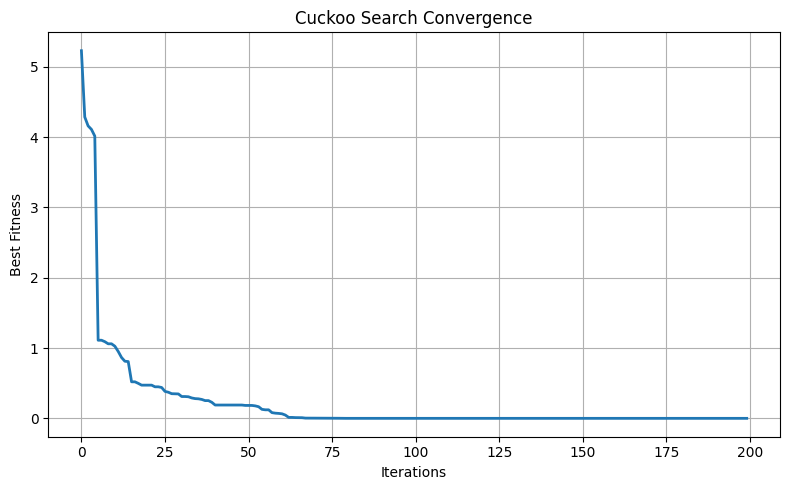

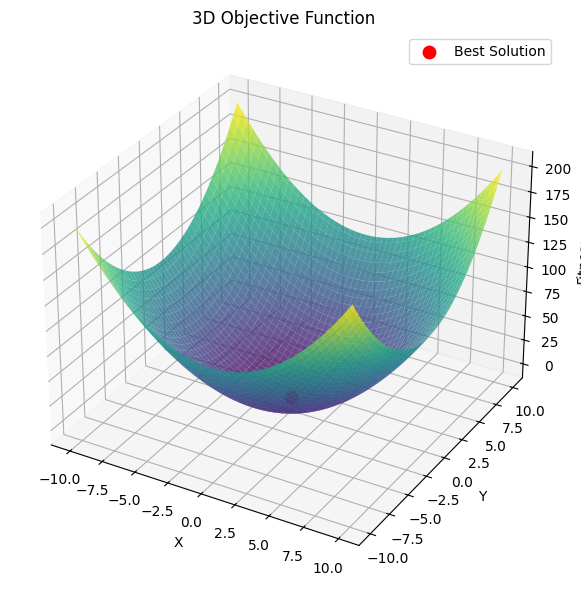

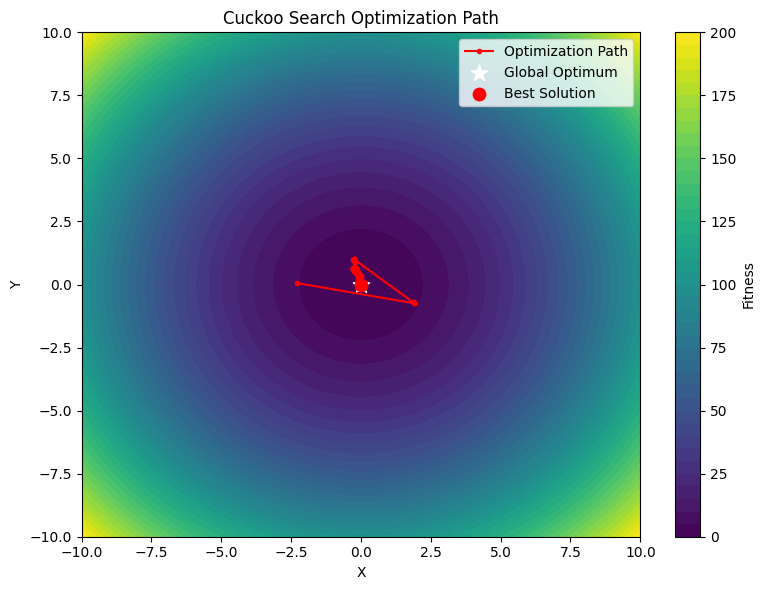

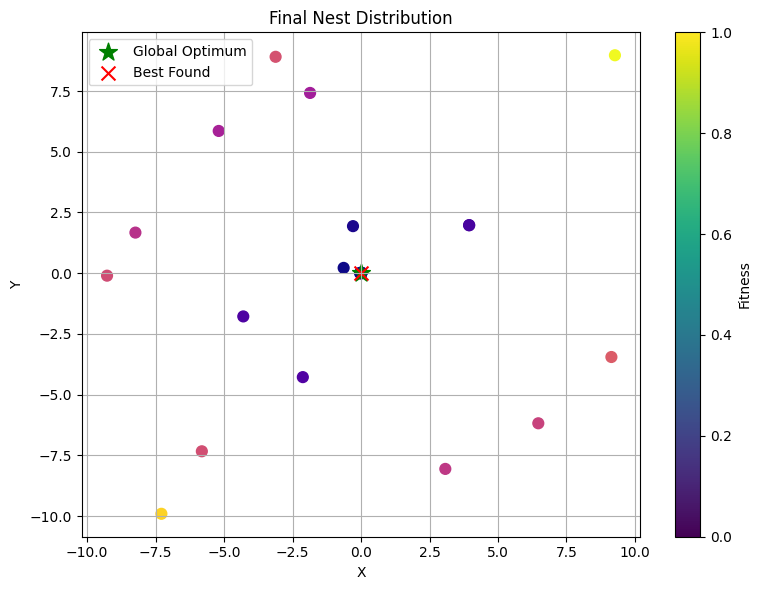

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma

# Cuckoo Search parameters
N = 25
PA = 0.25
ITERATIONS = 200
DIM = 2
LOWER = -10
UPPER = 10
ALPHA = 0.01
BETA = 1.5

# Objective function: Sphere function
def objective(x):
    return np.sum(x ** 2)

# Levy flight using Mantegna's algorithm
def levy_flight():
    sigma = (
        gamma(1 + BETA) * np.sin(np.pi * BETA / 2)
        / (gamma((1 + BETA) / 2) * BETA
           * 2 ** ((BETA - 1) / 2))
    ) ** (1 / BETA)

    u = np.random.normal(0, sigma, DIM)
    v = np.random.normal(0, 1, DIM)

    return u / (np.abs(v) ** (1 / BETA))

# Initialize nests
nests = np.random.uniform(LOWER, UPPER, (N, DIM))
fitness = np.array([objective(x) for x in nests])

best_index = np.argmin(fitness)
best_solution = nests[best_index].copy()
best_fitness = fitness[best_index]

history = []
best_path = []

# Main Cuckoo Search loop
for iteration in range(ITERATIONS):

    for i in range(N):

        new_solution = nests[i] + ALPHA * levy_flight()
        new_solution = np.clip(new_solution, LOWER, UPPER)

        j = np.random.randint(N)

        if objective(new_solution) < fitness[j]:
            nests[j] = new_solution
            fitness[j] = objective(new_solution)

    # Abandon a fraction of poor nests
    abandoned = np.random.rand(N) < PA

    for i in range(N):
        if abandoned[i]:
            nests[i] = np.random.uniform(LOWER, UPPER, DIM)
            fitness[i] = objective(nests[i])

    # Update global best
    current_index = np.argmin(fitness)

    if fitness[current_index] < best_fitness:
        best_fitness = fitness[current_index]
        best_solution = nests[current_index].copy()

    history.append(best_fitness)
    best_path.append(best_solution.copy())

print("Best Solution:", best_solution)
print("Best Fitness:", best_fitness)

# Create objective function surface
x = np.linspace(LOWER, UPPER, 100)
y = np.linspace(LOWER, UPPER, 100)
X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2

# Plot 1: Convergence graph
plt.figure(figsize=(8, 5))
plt.plot(history, linewidth=2)
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Cuckoo Search Convergence")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 2: 3D objective function
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.8)
ax.scatter(
    best_solution[0],
    best_solution[1],
    best_fitness,
    color="red", s=80, label="Best Solution"
)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Fitness")
ax.set_title("3D Objective Function")
ax.legend()
plt.tight_layout()
plt.show()

# Plot 3: Contour and optimized solution
plt.figure(figsize=(8, 6))
plt.contourf(X, Y, Z, levels=40, cmap="viridis")
plt.colorbar(label="Fitness")

path = np.array(best_path)
plt.plot(path[:, 0], path[:, 1], "r.-",
         label="Optimization Path")
plt.scatter(0, 0, color="white", marker="*", s=150,
            label="Global Optimum")
plt.scatter(best_solution[0], best_solution[1],
            color="red", s=80, label="Best Solution")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Cuckoo Search Optimization Path")
plt.legend()
plt.tight_layout()
plt.show()

# Plot 4: Final nest distribution
plt.figure(figsize=(8, 6))
plt.scatter(nests[:, 0], nests[:, 1], c=fitness,
            cmap="plasma", s=60)
plt.scatter(0, 0, color="green", marker="*",
            s=180, label="Global Optimum")
plt.scatter(best_solution[0], best_solution[1],
            color="red", marker="x", s=100,
            label="Best Found")
plt.colorbar(label="Fitness")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Final Nest Distribution")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



CLOUD-BASED CUCKOO SEARCH RESULTS
---------------------------------
Best Solution: [ 3.84489246e-09 -5.34780501e-10]
Best Fitness: 1.5069188199593056e-17


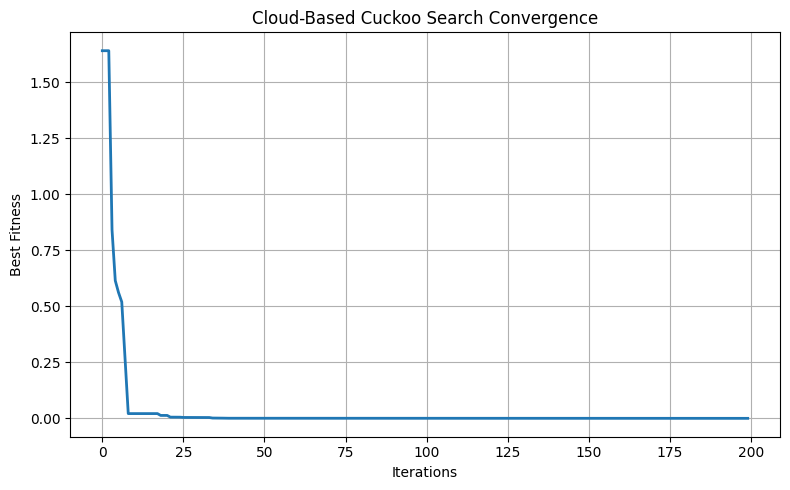

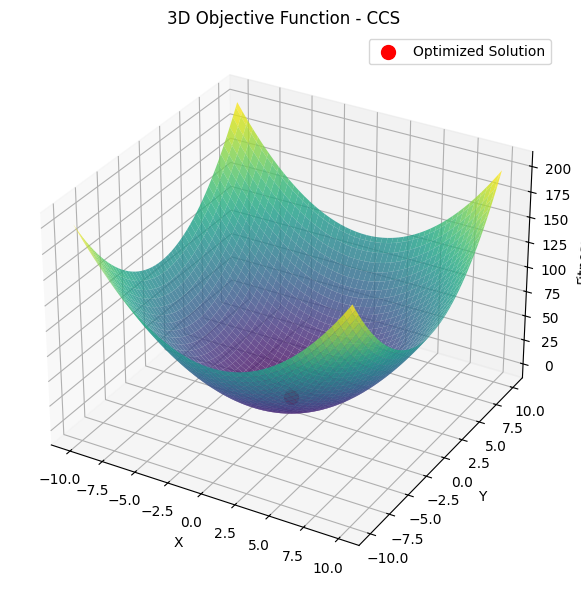

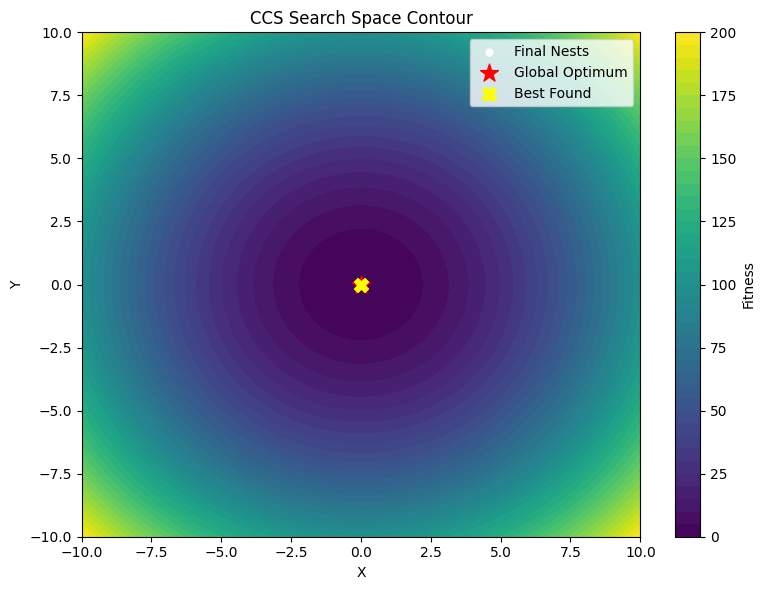

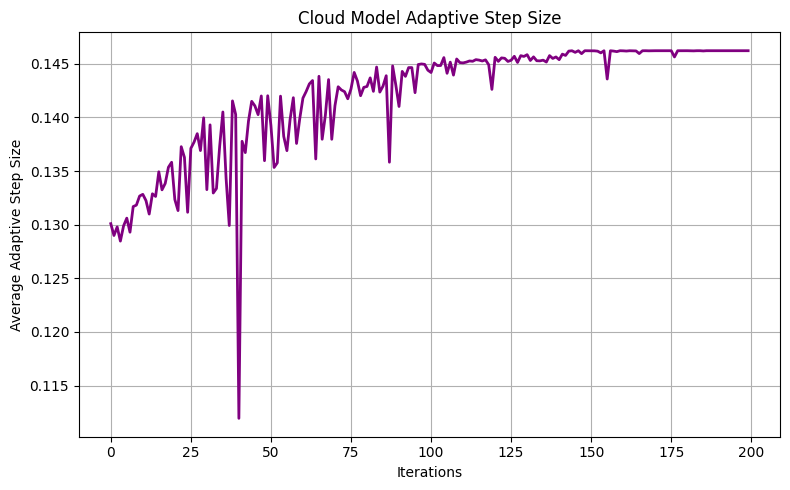

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma

# ---------------- PARAMETERS ----------------

N = 50
DIM = 2
ITERATIONS = 200

PA = 0.25
GAMMA = 0.2
BETA = 1.5

LOWER = -10
UPPER = 10

rng = np.random.default_rng(42)

# ---------------- OBJECTIVE FUNCTION ----------------

def objective(x):
    return np.sum(x ** 2)

# ---------------- LEVY FLIGHT ----------------

def levy_flight():

    sigma_u = (
        gamma(1 + BETA) * np.sin(np.pi * BETA / 2)
        / (
            gamma((1 + BETA) / 2)
            * BETA
            * 2 ** ((BETA - 1) / 2)
        )
    ) ** (1 / BETA)

    u = rng.normal(0, sigma_u, DIM)
    v = rng.normal(0, 1, DIM)

    return u / (np.abs(v) ** (1 / BETA) + 1e-12)

# ---------------- CLOUD MODEL ----------------

def cloud_model(fitness):

    best = np.min(fitness)
    average = np.mean(fitness)

    Ex = best
    En = max(average - best, 0)
    He = En / 5

    # Generate cloud entropy
    sigma = abs(rng.normal(En, np.sqrt(He)))

    sigma = max(sigma, 1e-12)

    return Ex, En, He, sigma

# ---------------- MEMBERSHIP DEGREE ----------------

def membership_degree(f, Ex, sigma):

    return np.exp(
        -((f - Ex) ** 2) / (2 * sigma ** 2)
    )

# ---------------- ADAPTIVE STEP SIZE ----------------

def adaptive_step_size(mu):

    return GAMMA / (1 + np.exp(-mu))

# ---------------- INITIALIZATION ----------------

nests = rng.uniform(
    LOWER, UPPER, (N, DIM)
)

fitness = np.array([
    objective(x) for x in nests
])

best_index = np.argmin(fitness)

best_solution = nests[best_index].copy()
best_fitness = fitness[best_index]

history = []
alpha_history = []

# ---------------- MAIN CCS ALGORITHM ----------------

for iteration in range(ITERATIONS):

    # Calculate cloud model characteristics
    Ex, En, He, sigma = cloud_model(fitness)

    alpha_values = []

    # Levy flight and greedy selection
    for i in range(N):

        mu = membership_degree(
            fitness[i], Ex, sigma
        )

        alpha0 = adaptive_step_size(mu)
        alpha_values.append(alpha0)

        alpha = alpha0 * (nests[i] - best_solution)

        new_solution = (
            nests[i] + alpha * levy_flight()
        )

        new_solution = np.clip(
            new_solution, LOWER, UPPER
        )

        new_fitness = objective(new_solution)

        # Greedy selection
        if new_fitness < fitness[i]:

            nests[i] = new_solution
            fitness[i] = new_fitness

    # Biased random walk / nest abandonment
    abandoned = rng.random(N) < PA

    for i in np.where(abandoned)[0]:

        j, k = rng.choice(N, 2, replace=False)

        step = rng.random() * (
            nests[j] - nests[k]
        )

        new_solution = nests[i] + step

        new_solution = np.clip(
            new_solution, LOWER, UPPER
        )

        new_fitness = objective(new_solution)

        if new_fitness < fitness[i]:

            nests[i] = new_solution
            fitness[i] = new_fitness

    # Update global best
    current_index = np.argmin(fitness)

    if fitness[current_index] < best_fitness:

        best_fitness = fitness[current_index]
        best_solution = nests[current_index].copy()

    history.append(best_fitness)
    alpha_history.append(np.mean(alpha_values))

# ---------------- RESULTS ----------------

print("\nCLOUD-BASED CUCKOO SEARCH RESULTS")
print("---------------------------------")
print("Best Solution:", best_solution)
print("Best Fitness:", best_fitness)

# ---------------- OBJECTIVE SURFACE ----------------

x = np.linspace(LOWER, UPPER, 100)
y = np.linspace(LOWER, UPPER, 100)

X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2

# ---------------- GRAPH 1: CONVERGENCE ----------------

plt.figure(figsize=(8, 5))

plt.plot(history, linewidth=2)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Cloud-Based Cuckoo Search Convergence")

plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------- GRAPH 2: 3D SURFACE ----------------

fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    alpha=0.8
)

ax.scatter(
    best_solution[0],
    best_solution[1],
    best_fitness,
    color="red",
    s=100,
    label="Optimized Solution"
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Fitness")

ax.set_title("3D Objective Function - CCS")
ax.legend()

plt.tight_layout()
plt.show()

# ---------------- GRAPH 3: CONTOUR ----------------

plt.figure(figsize=(8, 6))

plt.contourf(
    X, Y, Z,
    levels=40,
    cmap="viridis"
)

plt.colorbar(label="Fitness")

plt.scatter(
    nests[:, 0],
    nests[:, 1],
    color="white",
    s=25,
    label="Final Nests"
)

plt.scatter(
    0, 0,
    color="red",
    marker="*",
    s=180,
    label="Global Optimum"
)

plt.scatter(
    best_solution[0],
    best_solution[1],
    color="yellow",
    marker="X",
    s=100,
    label="Best Found"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("CCS Search Space Contour")

plt.legend()
plt.tight_layout()
plt.show()

# ---------------- GRAPH 4: ADAPTIVE STEP SIZE ----------------

plt.figure(figsize=(8, 5))

plt.plot(
    alpha_history,
    color="purple",
    linewidth=2
)

plt.xlabel("Iterations")
plt.ylabel("Average Adaptive Step Size")
plt.title("Cloud Model Adaptive Step Size")

plt.grid(True)
plt.tight_layout()
plt.show()


In [4]:
sigma = abs(rng.normal(En, np.sqrt(He)))
sigma = max(sigma, 1e-12)

mu = membership_degree(
    fitness[i], Ex, sigma
)